# YOLO26n — kết quả huấn luyện theo gold

Trần Xuân Bắc — 2A202603132 — L2A.

Phiên huấn luyện thực tế chạy bằng `tools/train_gold.py` trên máy local, dùng gold làm nhãn train theo yêu cầu học viên. Notebook này đọc kết quả thật và hiển thị đồ thị, chỉ số, 10 ảnh prediction; không phải phiên Google Colab đã train.

Raw IDs của gold/eval: **0 car, 1 van, 2 truck, 3 bus**. Train gồm 50 ảnh và 653 box; validation gồm 10 ảnh và 113 box, đồng thời dùng chọn best checkpoint. Bản CP4 và kết quả raw ban đầu F1=0,4926 được giữ để truy vết. Sau phiên gold_reference, student được rework và đạt F1=0,9508, mean IoU=0,8488; xem báo cáo cá nhân. Các chỉ số model trong notebook vẫn thuộc lần train trực tiếp bằng gold.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

ROOT = Path.cwd()
if not (ROOT / 'tools/train_gold.py').is_file() and (ROOT.parent / 'tools/train_gold.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'tools/train_gold.py').is_file():
    target = Path('/content/Day2-Gold-Results') if Path('/content').is_dir() else ROOT / 'Day2-Gold-Results'
    if not target.exists():
        subprocess.run(['git', 'clone', 'https://github.com/trxuanbac/K5-L2A-DAY02-TranXuanBac-2A202603132-ObjectDetection', str(target)], check=True)
    ROOT = target
ASSETS = ROOT / 'report/individual/assets'
print('Repo:', ROOT.resolve())


Repo: /Users/chuoi/K5-L2-/K5-L2-Day02-ObjectDetection


In [2]:
# Mặc định chỉ đọc kết quả của phiên chạy đã hoàn tất.
# Muốn train lại: cần gold local và checkpoint pretrained; không upload gold lên GitHub.
RERUN_TRAINING = False
if RERUN_TRAINING:
    weights = ROOT / 'outputs/gold_training/yolo26n.pt'
    assert weights.is_file(), 'Đặt checkpoint pretrained yolo26n.pt vào outputs/gold_training/ trước.'
    assert (ROOT / 'gold_train_labels').is_dir(), 'Cần gold labels local.'
    subprocess.run([sys.executable, str(ROOT / 'tools/train_gold.py'),
                    '--gold-labels', str(ROOT / 'gold_train_labels'),
                    '--weights', str(weights), '--epochs', '50', '--batch', '8', '--device', 'cpu'],
                   cwd=ROOT, check=True)
else:
    print('Đọc artifact thật từ lần train CLI; không chạy lại training.')


Đọc artifact thật từ lần train CLI; không chạy lại training.


In [3]:
from IPython.display import display, Markdown, Image
metrics_file = ASSETS / 'model_eval_metrics_gold.json'
assert metrics_file.is_file(), 'Phiên train chưa hoàn tất hoặc chưa có artifact kết quả.'
m = json.loads(metrics_file.read_text())
assert m['experiment'] == 'gold_reference' and m['epochs_completed'] == 50
print('Label source:', m['label_source'])
print('Epochs:', m['epochs_completed'], 'device:', m['device'])
print('Checkpoint:', m['checkpoint'])
rows = ['| Metric | Value |', '|---|---:|']
for key in ['precision', 'recall', 'map50', 'map50_95']:
    rows.append(f"| {key} | {m[key]:.6f} |")
display(Markdown('\n'.join(rows)))
rows = ['| Class | Precision | Recall | mAP50 | mAP50–95 |', '|---|---:|---:|---:|---:|']
for name, values in m['per_class'].items():
    rows.append(f"| {name} | {values['precision']:.4f} | {values['recall']:.4f} | {values['map50']:.4f} | {values['map50_95']:.4f} |")
display(Markdown('\n'.join(rows)))
print('Eval role:', m['eval_role'])


Label source: gold, not student annotations
Epochs: 50 device: cpu
Checkpoint: /Users/chuoi/K5-L2-/K5-L2-Day02-ObjectDetection/outputs/gold_training/yolo26_runs/vehicle_gold/weights/best.pt


| Metric | Value |
|---|---:|
| precision | 0.518141 |
| recall | 0.646748 |
| map50 | 0.645446 |
| map50_95 | 0.451602 |

| Class | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|
| car | 0.7272 | 0.8936 | 0.9069 | 0.6348 |
| van | 0.2474 | 0.4648 | 0.4828 | 0.3301 |
| truck | 0.4123 | 0.5000 | 0.4950 | 0.3960 |
| bus | 0.6857 | 0.7286 | 0.6971 | 0.4454 |

Eval role: validation and checkpoint selection, not an independent test set


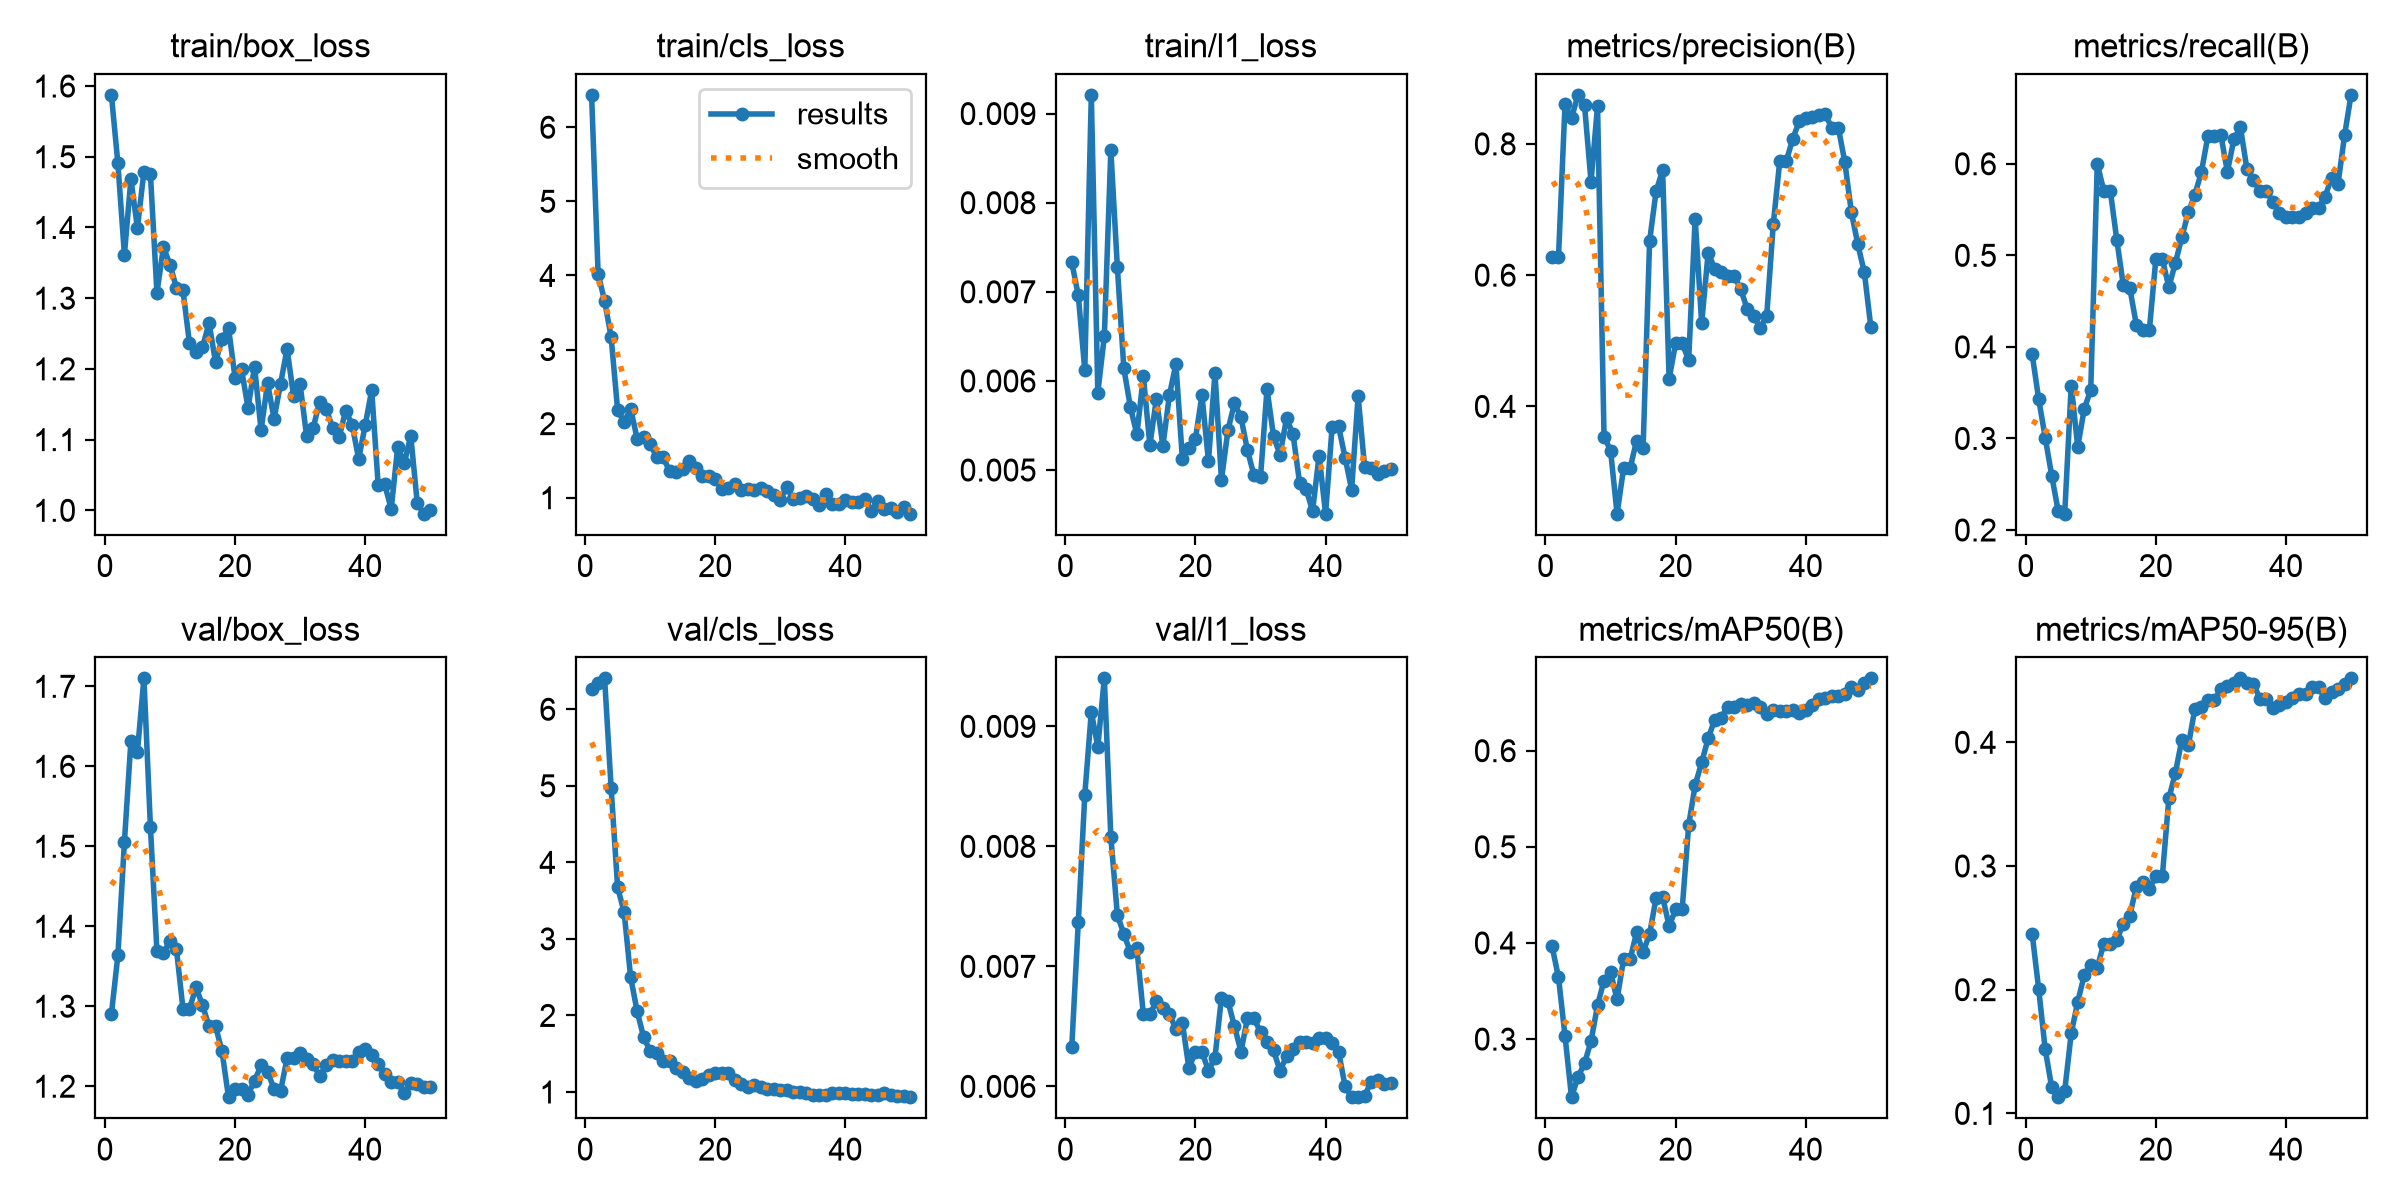

In [4]:
run_name = Path(m['train_run']).name
plot = ASSETS / 'yolo26_runs' / run_name / 'results.png'
assert plot.is_file()
display(Image(filename=str(plot)))


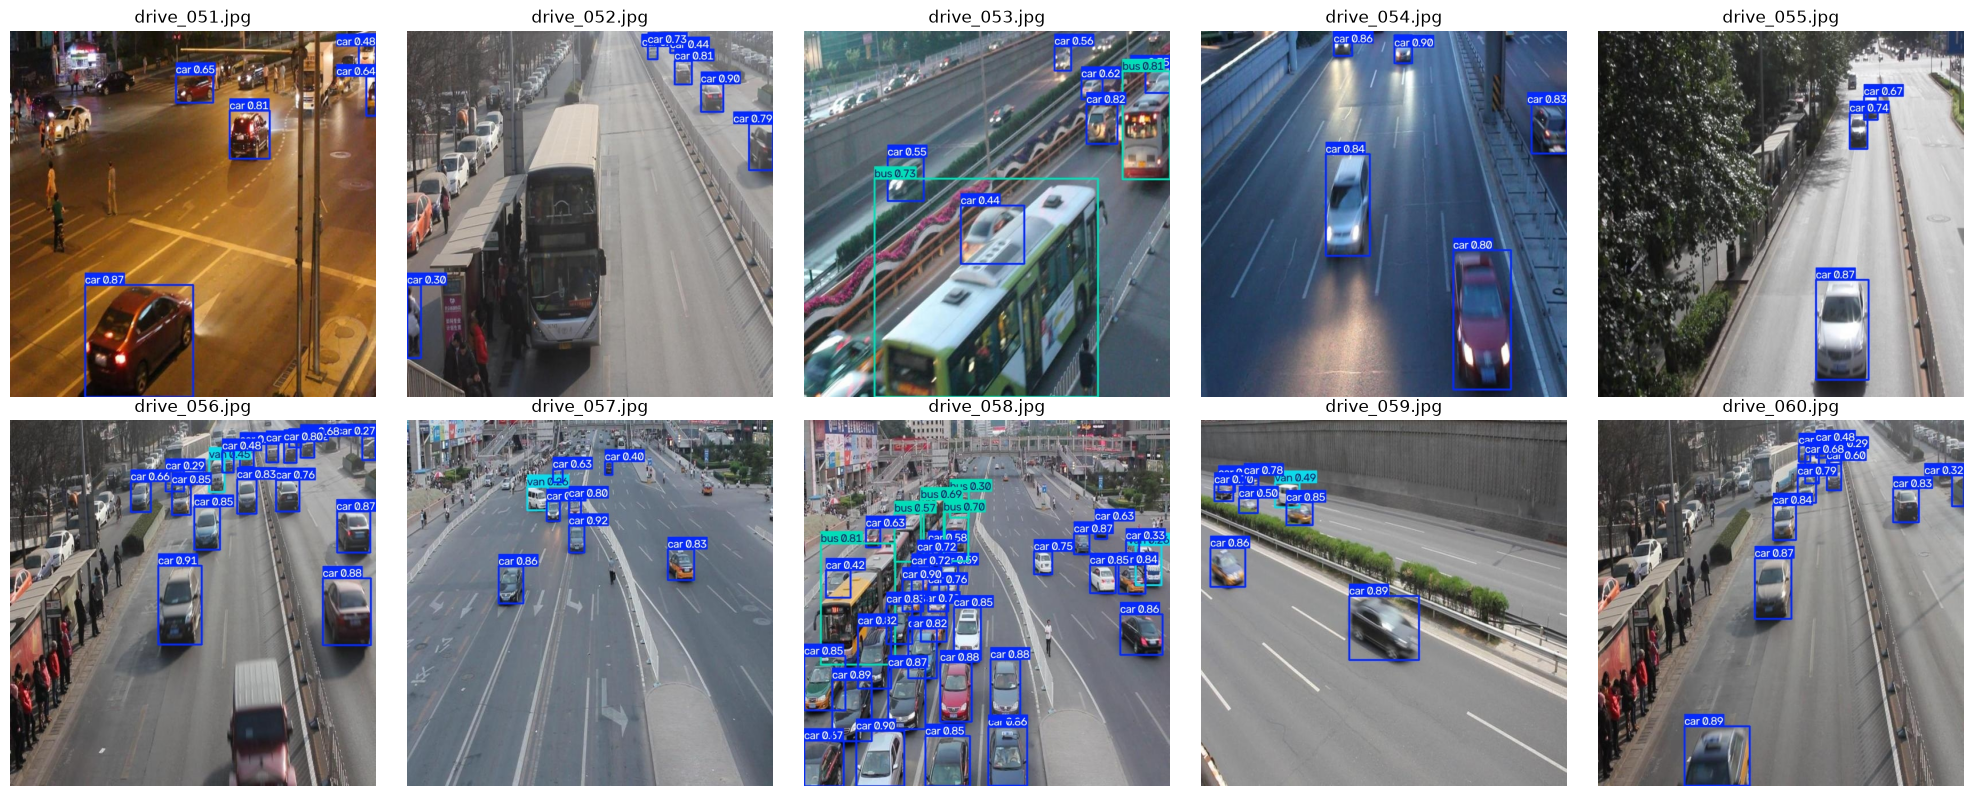

In [5]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage
images = sorted((ASSETS / m['published_prediction_dir']).glob('*.jpg'))
assert len(images) == 10
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, image in zip(axes.flat, images):
    ax.imshow(PILImage.open(image))
    ax.set_title(image.name)
    ax.axis('off')
plt.tight_layout()
plt.show()


In [6]:
lowest = min(m['per_class'], key=lambda name: m['per_class'][name]['recall'])
print('Lớp có recall thấp nhất:', lowest, m['per_class'][lowest]['recall'])
print('mAP50 - mAP50–95:', m['map50'] - m['map50_95'])
print('Phải mở ảnh cụ thể để kiểm tra box và lỗi lớp; các số này không thay cho gold QC của nhãn học viên.')


Lớp có recall thấp nhất: van 0.46476600892756914
mAP50 - mAP50–95: 0.1938446004451687
Phải mở ảnh cụ thể để kiểm tra box và lỗi lớp; các số này không thay cho gold QC của nhãn học viên.


In [7]:
analysis_file = ASSETS / 'gold_prediction_analysis.json'
a = json.loads(analysis_file.read_text())
print('Diagnostic thresholds:', a['confidence'], a['iou_threshold'])
print('Image illustrating lowest-recall class:', a['illustration']['image'])
print('Counts:', a['illustration']['classes'][a['lowest_validation_recall_class']])
print('Matched boxes with IoU < 0.75:', a['matches_iou_below_075'], '/', a['matched_boxes'])
print('Wrong-class candidates:', a['wrong_class_examples'])


Diagnostic thresholds: 0.25 0.5
Image illustrating lowest-recall class: drive_052.jpg
Counts: {'gold': 1, 'predictions': 0, 'tp': 0, 'fn': 1, 'fp': 0}
Matched boxes with IoU < 0.75: 10 / 89
Wrong-class candidates: [{'image': 'drive_052.jpg', 'expected': 'van', 'predicted': 'car', 'iou': 0.9128}, {'image': 'drive_053.jpg', 'expected': 'van', 'predicted': 'car', 'iou': 0.7838}, {'image': 'drive_058.jpg', 'expected': 'truck', 'predicted': 'van', 'iou': 0.8781}, {'image': 'drive_060.jpg', 'expected': 'van', 'predicted': 'car', 'iou': 0.7983}]


## Giới hạn

- Eval đồng thời làm validation chọn checkpoint; không phải test set độc lập.
- Chạy đầu trên MPS rồi resume checkpoint đã lưu trên CPU do MPS ngừng cập nhật. Xem manifest và log local cho chi tiết.
- Đây là kết quả model train trên gold; không dùng chỉ số model để thay cho điểm annotation. CP5 sau đó đã được chấm lại thật trên nhãn student sau rework và đạt gate; kết quả trước/sau nằm trong báo cáo riêng.
- Notebook có thể xem kết quả đã commit trên GitHub/Colab; việc hiển thị kết quả không biến phiên train local thành phiên train Colab.